# When Outliers Matter: Investigating Gradient-Based Data Selection for Robust Learning

**UCLA CS 260D — Final Project | Fall 2026**

## 1. Dataset Exploration: SpuCoMNIST

### 1.1 Introduction

Deep learning models often exploit **spurious correlations**, which are statistical relationships between input features and labels that do not necessarily reflect the true classification task. Models trained on such data may achieve high average accuracy but perform poorly on minority examples that violate these correlations.

In this project, we investigate whether **EPIC (Effective Poison Identification)**, a gradient-based data filtering method originally developed to defend against data poisoning, can effectively handle datasets containing spurious correlations. In particular, we examine whether removing isolated examples in gradient space may unintentionally discard informative minority examples.

We use **SpuCoMNIST**, a synthetic benchmark based on MNIST handwritten digits, to conduct controlled experiments.

### 1.2 Objectives

The objectives of this notebook are to:

1. Load and inspect the SpuCoMNIST dataset.
2. Examine the distribution of majority and minority groups.
3. Visualize examples from each group.
4. Verify the dataset configuration before training and evaluating robust learning methods.

### 1.3 Dataset Configuration

| Parameter | Configuration |
|---|---|
| Dataset | SpuCoMNIST |
| Classification task | Binary classification |
| Class 0 | Digits 0–4 |
| Class 1 | Digits 5–9 |
| Spurious feature | Background color |
| Spurious correlation strength | 95% |
| Spurious feature difficulty | MAGNITUDE_LARGE |
| Random seed | 42 |
| Dataset split | Training |

A correlation strength of 95% creates a strongly biased training distribution in which most examples follow the class–background association, while approximately 5% violate it.

These minority examples are particularly important for evaluating whether a model learns the actual digit features or relies on background-color shortcuts.

### 1.4 Loading and Initializing SpuCoMNIST

We load the training split using the official SpuCo Python package. The dataset has already been downloaded locally, so `download=False` prevents unnecessary downloads.

We initialize the dataset with a fixed random seed to ensure reproducibility. After initialization, we inspect the total number of training examples and the size of each group.

Each group is represented as a tuple `(class_label, spurious_label)`. Groups where the two labels match are majority groups, while groups where they differ are minority groups under the current dataset configuration.

In [1]:

# ============================================================
# CS 260D Final Project
# Section 1: Dataset Exploration
# ============================================================

# Import the dataset and experiment utilities.
from spuco.datasets import SpuCoMNIST, SpuriousFeatureDifficulty
from spuco.utils import set_seed

# Libraries for subsequent analysis and visualization.
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. Set random seed for reproducibility
# ------------------------------------------------------------

RANDOM_SEED = 42
set_seed(RANDOM_SEED)

# ------------------------------------------------------------
# 2. Define the dataset configuration
# ------------------------------------------------------------

DATA_ROOT = "./data"
SPURIOUS_CORRELATION = 0.95

# Binary classification:
# Class 0: MNIST digits 0, 1, 2, 3, 4
# Class 1: MNIST digits 5, 6, 7, 8, 9
DIGIT_CLASSES = [
    [0, 1, 2, 3, 4],
    [5, 6, 7, 8, 9]
]

# ------------------------------------------------------------
# 3. Initialize SpuCoMNIST training dataset
# ------------------------------------------------------------

dataset = SpuCoMNIST(
    root=DATA_ROOT,
    spurious_feature_difficulty=(
        SpuriousFeatureDifficulty.MAGNITUDE_LARGE
    ),
    classes=DIGIT_CLASSES,
    spurious_correlation_strength=SPURIOUS_CORRELATION,
    split="train",
    download=False,
)

# Generate the spurious-correlated training examples.
dataset.initialize()

# ------------------------------------------------------------
# 4. Examine group distribution
# ------------------------------------------------------------

print("=" * 55)
print("SpuCoMNIST — Dataset Summary")
print("=" * 55)

print(f"Random seed: {RANDOM_SEED}")
print(f"Spurious correlation: {SPURIOUS_CORRELATION:.0%}")
print(f"Total training examples: {len(dataset):,}")

print("\nGroup Distribution")
print("-" * 55)

for group, indices in sorted(dataset.group_partition.items()):
    count = len(indices)
    percentage = count / len(dataset) * 100

    group_type = (
        "Majority" if group[0] == group[1]
        else "Minority"
    )

    print(
        f"Group {group} [{group_type}]: "
        f"{count:,} samples ({percentage:.2f}%)"
    )

print("=" * 55)


/Users/lijuntao/Desktop/mydesktop/UCLA/courses/COMSCI260D/260d_final_project/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SpuCoMNIST — Dataset Summary
Random seed: 42
Spurious correlation: 95%
Total training examples: 48,004

Group Distribution
-------------------------------------------------------
Group (0, 0) [Majority]: 23,255 samples (48.44%)
Group (0, 1) [Minority]: 1,224 samples (2.55%)
Group (1, 0) [Minority]: 1,177 samples (2.45%)
Group (1, 1) [Majority]: 22,348 samples (46.55%)


### 1.5 Visualizing Majority and Minority Groups

To better understand the spurious correlations in SpuCoMNIST, we visualize representative examples from each of the four groups.

Each group is identified by `(class_label, spurious_label)`:

- **(0, 0):** Majority examples from class 0.
- **(0, 1):** Minority examples from class 0.
- **(1, 0):** Minority examples from class 1.
- **(1, 1):** Majority examples from class 1.

The majority groups follow the dominant relationship between digit labels and background colors. Minority examples violate this relationship.

These minority examples are particularly important because they help us evaluate whether a model learns the digit patterns or relies on background colors.

**Objective:** Visually inspect the differences between majority and minority groups before evaluating data filtering methods such as EPIC.

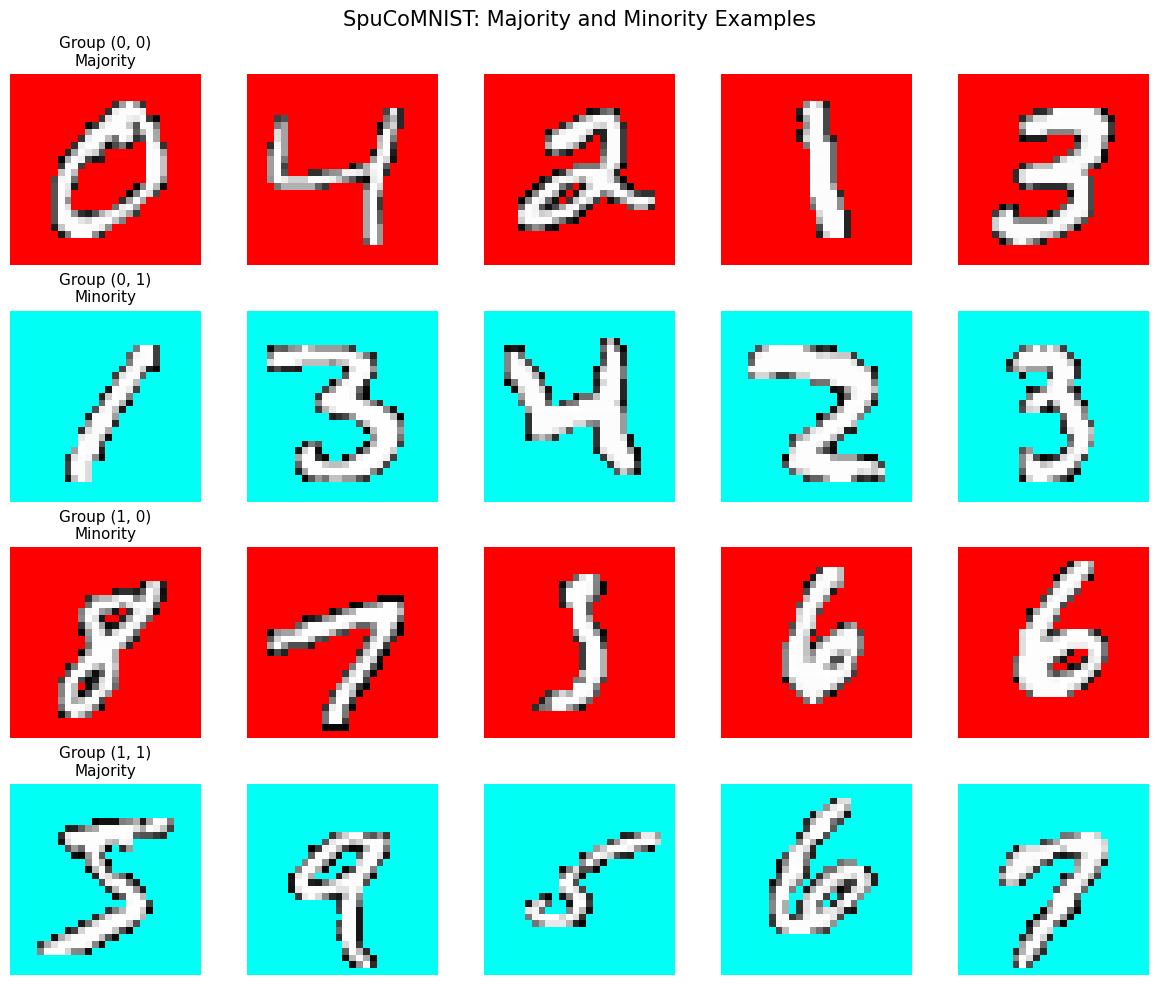

Visualization saved successfully!


In [2]:

# ============================================================
# 1.5 Visualize majority and minority groups
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Sort the four groups for consistent visualization.
groups = sorted(dataset.group_partition.keys())

# Display five examples from each group.
fig, axes = plt.subplots(4, 5, figsize=(12, 10))

for row, group in enumerate(groups):
    indices = dataset.group_partition[group]

    for col, idx in enumerate(indices[:5]):
        image, label = dataset[idx]

        # Convert tensors or PIL images to NumPy arrays.
        if hasattr(image, "detach"):
            image = image.detach().cpu().numpy()

        image = np.asarray(image)

        # Convert channel-first format (C, H, W)
        # to channel-last format (H, W, C).
        if image.ndim == 3 and image.shape[0] in (1, 3):
            image = np.transpose(image, (1, 2, 0))

        axes[row, col].imshow(image)
        axes[row, col].axis("off")

        # Label each row with its group information.
        if col == 0:
            group_type = (
                "Majority" if group[0] == group[1]
                else "Minority"
            )
            axes[row, col].set_title(
                f"Group {group}\n{group_type}",
                fontsize=11,
            )

plt.suptitle(
    "SpuCoMNIST: Majority and Minority Examples",
    fontsize=15,
)

plt.tight_layout()
plt.savefig(
    "spucomnist_visualization.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("Visualization saved successfully!")


### 1.6 Initial Observations

The SpuCoMNIST training dataset contains **48,004 examples**, with approximately **95% majority-group examples and 5% minority-group examples**.

The visualization confirms that background color is strongly correlated with class labels:

- **Class 0 (digits 0–4):** Most examples have cyan backgrounds, while minority examples have red backgrounds.
- **Class 1 (digits 5–9):** Most examples have red backgrounds, while minority examples have cyan backgrounds.

Although background color is unrelated to the actual digit classification task, it provides an easy predictive shortcut during training.

This creates a controlled environment for investigating whether gradient-based data filtering methods, particularly EPIC, disproportionately remove minority examples that violate the dominant color–label relationship.

**Research hypothesis:** If minority examples occupy relatively isolated regions in gradient space, EPIC may identify them as outliers and remove them, potentially reducing worst-group classification accuracy.

This hypothesis will be tested experimentally rather than assumed to hold.